# 06 · Final evaluation on the test window

Supports **Sections 7.1–7.7, 7.9 and 7.10** of the thesis. This is the first and only use of the test window
(d_1942–d_1969, 23.05.–19.06.2016.). Every model was fixed before it was opened: the classical methods have
no tuned parameters, and each XGBoost model is its best validation trial refitted on targets up to d_1941.
The forecasts are built by `python src/evaluation.py`; this notebook only scores them.

As on the validation window, the 28 days are forecast 7 days at a time from 4 weekly origins, without
refitting. The scales and weights of RMSSE and WRMSSE are the official M5 ones (history up to d_1941).

Two measures are reported throughout, because they answer different questions:

- **WRMSSE**: the M5 score, the mean over the 12 hierarchy levels of the revenue-weighted RMSSE of the
  aggregated forecasts. It rewards getting totals right.
- **Mean RMSSE**: the unweighted mean of RMSSE over the 30,490 item × store series. It measures accuracy on
  single series, most of which are intermittent.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import evaluation as E
import factorial_stats as S
import m5_data as m5
import metrics as M
from plot_style import CONTEXT, INK_SECONDARY, SERIES, apply_style, savefig

apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
RESULTS = ROOT / "results" / "evaluation"
RESULTS.mkdir(parents=True, exist_ok=True)
RUNS = m5.PROCESSED_DIR / "global_xgb"

INPUTS = {"L": "L", "LE": "L+E", "LES": "L+E+S", "LESID": "L+E+S+ID"}
LOSSES = {"mse": "MSE", "poisson": "Poisson", "tweedie": "Tweedie"}
KINDS = {"": "", "per_store": "per store", "per_store_cat": "per store × category", "per_class": "per demand class",
         "recursive": "recursive"}
BM = {"naive": "Naive", "snaive": "Seasonal naive", "mean": "Mean", "croston": "Croston", "sba": "SBA", "tsb": "TSB",
      "adida": "ADIDA"}
LEVEL_NAMES = {1: "Total", 2: "State", 3: "Store", 4: "Category", 5: "Department", 6: "State × category",
               7: "State × department", 8: "Store × category", 9: "Store × department", 10: "Item",
               11: "Item × state", 12: "Item × store"}
CLASSES = ["smooth", "erratic", "intermittent", "lumpy"]


def label(key):
    if key.startswith("benchmark_"):
        return BM[key[10:]]
    inputs, loss, *rest = key.split("_", 2)
    kind = KINDS[rest[0]] if rest else ""
    return f"{INPUTS[inputs]} · {LOSSES[loss]}" + (f" · {kind}" if kind else "")


raw = np.load(E.OUT)
test = {label(k): raw[k] for k in raw.files if not k.startswith("sample100_") and "_seed" not in k}
seeds_fc = {k: raw[k] for k in raw.files if "_seed" in k}
sample_fc = {k[10:]: raw[k] for k in raw.files if k.startswith("sample100_")}

valid = {BM[m]: f for m, f in ((k[6:], v) for k, v in np.load(m5.PROCESSED_DIR / "forecasts" / "benchmarks.npz").items())}
for f in RUNS.glob("*/*/valid_forecast.npy"):
    valid[label(f.parent.name)] = np.load(f)
assert set(valid) == set(test)

ev_test = E.test_evaluator()
ev_valid = M.Evaluator.for_origin(m5.TRAIN_END, (m5.TRAIN_END + 1, m5.VALID_END))
stats = pd.read_parquet(m5.PROCESSED_DIR / "series_stats_train.parquet")
cls = stats["sbc_class"].astype(str).to_numpy()

XGB = [m for m in test if m not in BM.values()]
GLOBAL = sorted([m for m in XGB if m.count("·") == 1],
                key=lambda m: (list(INPUTS.values()).index(m.split(" · ")[0]), list(LOSSES.values()).index(m.split(" · ")[1])))
OTHER = [m for m in XGB if m not in GLOBAL]
ORDER = list(BM.values()) + GLOBAL + sorted(OTHER)
print(f"{len(BM)} classical methods, {len(GLOBAL)} global variants, {len(OTHER)} partially global and recursive models")

C:\Users\ilin.j\AppData\Roaming\Python\Python312\site-packages\hyperopt\atpe.py:19: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


7 classical methods, 10 global variants, 8 partially global and recursive models


## 1. All models: validation and test (Sections 7.1, 7.3, 7.4)

The validation columns are optimistic for the XGBoost models, which were tuned on that window. The test
columns are the result.

In [2]:
score = {w: {m: ev.wrmsse(fc[m]) for m in ORDER} for w, ev, fc in [("valid", ev_valid, valid), ("test", ev_test, test)]}
bottom = {w: {m: ev.bottom(fc[m]) for m in ORDER} for w, ev, fc in [("valid", ev_valid, valid), ("test", ev_test, test)]}
rmsse = pd.DataFrame({m: bottom["test"][m]["rmsse"] for m in ORDER})
summary = pd.DataFrame({"WRMSSE valid": {m: score["valid"][m]["all"] for m in ORDER},
                        "WRMSSE test": {m: score["test"][m]["all"] for m in ORDER},
                        "RMSSE mean valid": {m: bottom["valid"][m]["rmsse"].mean() for m in ORDER},
                        "RMSSE mean test": rmsse.mean(), "RMSSE median test": rmsse.median(),
                        "MASE mean test": {m: bottom["test"][m]["mase"].mean() for m in ORDER},
                        "bias test (scaled mean error)": {m: bottom["test"][m]["sme"].mean() for m in ORDER}})
summary.to_csv(RESULTS / "summary_test.csv")
out = rmsse.copy()
out.insert(0, "id", stats["id"].to_numpy())
out.to_csv(RESULTS / "rmsse_test.csv", index=False, float_format="%.5f")
BEST = summary.loc[GLOBAL, "WRMSSE valid"].idxmin()  # chosen on the validation window, not on the test window
print("best global variant on the validation window:", BEST)
summary.style.format("{:.3f}").background_gradient(cmap="Blues_r", subset=["WRMSSE test"]).background_gradient(
    cmap="Blues_r", subset=["RMSSE mean test"])

best global variant on the validation window: L+E+S+ID · Tweedie


,WRMSSE valid,WRMSSE test,RMSSE mean valid,RMSSE mean test,RMSSE median test,MASE mean test,bias test (scaled mean error)
Naive,1.753,1.605,1.043,1.050,0.954,1.327,0.199
Seasonal naive,0.924,0.901,1.011,1.033,0.965,1.241,0.001
Mean,1.206,1.081,0.793,0.797,0.708,1.112,-0.166
Croston,1.068,0.972,0.766,0.773,0.712,1.100,-0.001
SBA,1.094,0.961,0.765,0.771,0.711,1.084,-0.054
TSB,1.064,0.956,0.755,0.766,0.713,1.089,0.018
ADIDA,1.066,0.945,0.753,0.762,0.706,1.071,-0.040
L · MSE,0.701,0.692,0.748,0.758,0.706,1.114,0.042
L · Poisson,0.706,0.695,0.748,0.758,0.706,1.112,0.038
L · Tweedie,0.701,0.697,0.748,0.759,0.706,1.107,0.032


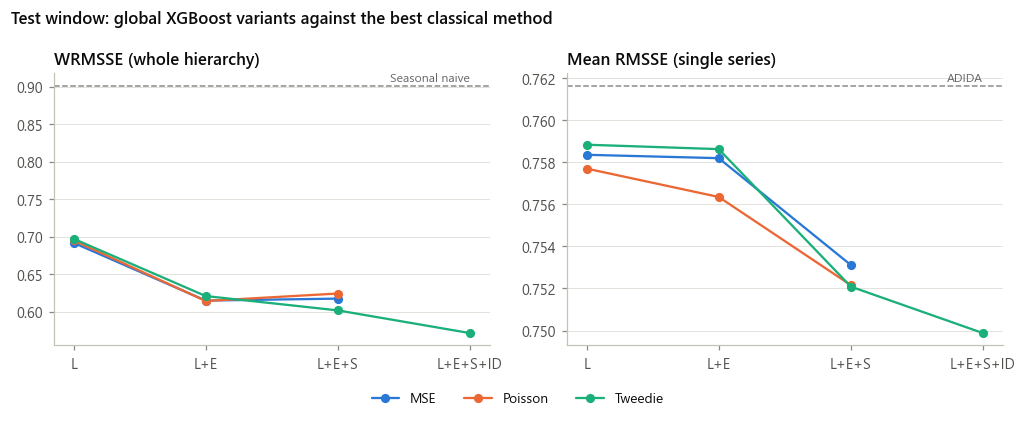

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.5))
sets = list(INPUTS.values())
for ax, col, title in zip(axes, ["WRMSSE test", "RMSSE mean test"], ["WRMSSE (whole hierarchy)", "Mean RMSSE (single series)"]):
    for loss, color in zip(LOSSES.values(), SERIES):
        v = [summary.loc[f"{i} · {loss}", col] if f"{i} · {loss}" in summary.index else np.nan for i in sets]
        ax.plot(range(len(sets)), v, color=color, marker="o", ms=5, label=loss)
    ref = "Seasonal naive" if col.startswith("WRMSSE") else summary.loc[list(BM.values()), col].idxmin()
    ax.axhline(summary.loc[ref, col], color="0.55", lw=1, ls="--")
    ax.annotate(ref, (len(sets) - 1, summary.loc[ref, col]), xytext=(0, 3), textcoords="offset points", ha="right",
                color="0.4", fontsize=8)
    ax.set_xticks(range(len(sets)), sets)
    ax.set_title(title)
fig.suptitle("Test window: global XGBoost variants against the best classical method", x=0.01, ha="left", fontsize=11,
             fontweight="semibold")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.02), ncols=3)
savefig(fig, "variants_test", subdir="evaluation")
plt.show()

## 2. By hierarchy level (Section 7.6)

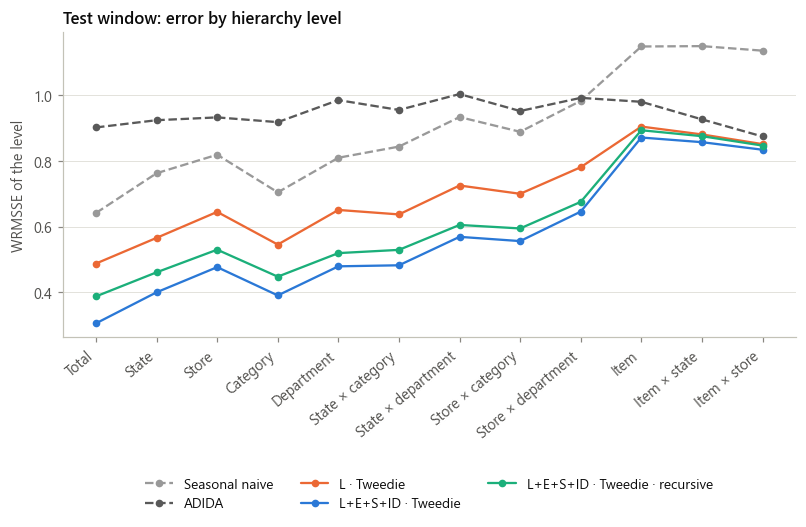

,Total,State,Store,Category,Department,State × category,State × department,Store × category,Store × department,Item,Item × state,Item × store
Seasonal naive,0.641,0.762,0.818,0.704,0.809,0.843,0.933,0.888,0.982,1.148,1.149,1.135
ADIDA,0.901,0.923,0.932,0.918,0.985,0.955,1.003,0.951,0.991,0.979,0.926,0.874
TSB,0.921,0.939,0.946,0.938,1.004,0.971,1.018,0.964,1.002,0.974,0.924,0.874
L · Tweedie,0.487,0.565,0.645,0.545,0.650,0.637,0.725,0.700,0.780,0.904,0.880,0.851
L+E · Tweedie,0.304,0.450,0.561,0.408,0.540,0.551,0.656,0.641,0.733,0.891,0.874,0.847
L+E+S · Tweedie,0.275,0.424,0.545,0.387,0.514,0.527,0.631,0.625,0.716,0.880,0.864,0.839
L+E+S+ID · Tweedie,0.305,0.400,0.476,0.390,0.479,0.482,0.569,0.556,0.645,0.871,0.857,0.834
L+E+S+ID · Tweedie · recursive,0.387,0.461,0.530,0.447,0.519,0.529,0.605,0.594,0.675,0.893,0.875,0.846


In [4]:
levels = pd.DataFrame({m: score["test"][m].drop("all") for m in ORDER}).T
levels.columns = [LEVEL_NAMES[int(c)] for c in levels.columns]
levels.to_csv(RESULTS / "wrmsse_by_level_test.csv")
SHOW = ["Seasonal naive", "ADIDA", "TSB", "L · Tweedie", "L+E · Tweedie", "L+E+S · Tweedie", BEST, f"{BEST} · recursive"]
fig, ax = plt.subplots(figsize=(8.6, 3.6))
colors = {"Seasonal naive": "0.6", "ADIDA": "0.35", BEST: SERIES[0], "L · Tweedie": SERIES[1], f"{BEST} · recursive": SERIES[2]}
for m in ["Seasonal naive", "ADIDA", "L · Tweedie", BEST, f"{BEST} · recursive"]:
    ax.plot(range(12), levels.loc[m].to_numpy(), color=colors[m], marker="o", ms=4, label=m,
            ls="--" if m in BM.values() else "-")
ax.set_xticks(range(12), levels.columns, rotation=40, ha="right")
ax.set_ylabel("WRMSSE of the level")
ax.set_title("Test window: error by hierarchy level")
ax.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.42))
savefig(fig, "wrmsse_by_level_test", subdir="evaluation")
plt.show()
levels.loc[SHOW].style.format("{:.3f}").background_gradient(cmap="Blues_r", axis=0)

## 3. By demand class (Section 7.5)

Mean RMSSE of the item × store series of each Syntetos–Boylan class, and the share of the series of the class
on which the best global variant has a lower RMSSE than ADIDA.

In [5]:
by_class = rmsse.groupby(cls).mean().T[CLASSES]
by_class.insert(0, "all", rmsse.mean())
by_class.to_csv(RESULTS / "rmsse_by_class_test.csv")
d = rmsse[BEST] - rmsse["ADIDA"]
wins = pd.DataFrame({"series": pd.Series(cls).value_counts(), f"{BEST} better than ADIDA": (d < 0).groupby(cls).mean(),
                     "tie": (d == 0).groupby(cls).mean(), "mean difference": d.groupby(cls).mean()}).loc[CLASSES]
display(by_class.loc[SHOW + ["Croston", "SBA"]].style.format("{:.3f}").background_gradient(cmap="Blues_r", axis=0))
wins.style.format("{:.3f}").format("{:,.0f}", subset=["series"])

,all,smooth,erratic,intermittent,lumpy
Seasonal naive,1.033,0.961,0.916,1.059,0.972
ADIDA,0.762,0.751,0.721,0.773,0.726
TSB,0.766,0.751,0.723,0.779,0.726
L · Tweedie,0.759,0.730,0.702,0.774,0.719
L+E · Tweedie,0.759,0.728,0.700,0.774,0.718
L+E+S · Tweedie,0.752,0.721,0.694,0.767,0.713
L+E+S+ID · Tweedie,0.750,0.719,0.691,0.765,0.709
L+E+S+ID · Tweedie · recursive,0.753,0.730,0.696,0.768,0.714
Croston,0.773,0.777,0.747,0.783,0.738
SBA,0.771,0.772,0.745,0.781,0.736


,series,L+E+S+ID · Tweedie better than ADIDA,tie,mean difference
smooth,"1,921",0.690,0.000,-0.032
erratic,874,0.690,0.000,-0.030
intermittent,"22,161",0.555,0.000,-0.008
lumpy,"5,534",0.589,0.000,-0.017


## 4. Local, partially global and global models (Section 7.2)

**All 30,490 series.** One model for all series, against one model per store, per store × category and per
demand class. The partially global models use the hyperparameters of the global model with the same inputs.

In [6]:
KEEP = ["Total", "Store", "Store × category", "Item × store"]
rows_ = []
for base in ["L+E+S · Tweedie", "L+E+S+ID · Tweedie"]:
    for kind, n in [("", 1), ("per store", 10), ("per store × category", 30), ("per demand class", 4)]:
        m = base + (f" · {kind}" if kind else "")
        rows_.append({"inputs": base.split(" · ")[0], "pooling": kind or "all series", "models": n,
                      "WRMSSE valid": summary.loc[m, "WRMSSE valid"], "WRMSSE test": summary.loc[m, "WRMSSE test"],
                      **{k: levels.loc[m, k] for k in KEEP}, "RMSSE mean test": summary.loc[m, "RMSSE mean test"]})
pooling = pd.DataFrame(rows_).set_index(["inputs", "pooling"])
pooling.to_csv(RESULTS / "pooling_test.csv")
pooling.style.format("{:.3f}").format("{:.0f}", subset=["models"])

**The sample of 100 series** (25 per demand class, notebook 05): one model per series against one model for
the 100 series and the model on all series. On the validation window the models per series looked far better
only because each was chosen on the days it was scored on; here no model has seen the days.

In [7]:
sample = pd.read_csv(ROOT / "results" / "local_xgb" / "sample.csv")
srow, scls = sample["row"].to_numpy(), sample["sbc_class"].to_numpy()
ev_s = E.test_evaluator(rows=srow)
s_rmsse = {}
for i in ["L", "LE", "LES"]:
    s_rmsse[("per series", INPUTS[i])] = ev_s.bottom(sample_fc[f"per_series_{i}"])["rmsse"].to_numpy()
for i in INPUTS:
    s_rmsse[("sample (100 series)", INPUTS[i])] = ev_s.bottom(sample_fc[f"sample_{i}"])["rmsse"].to_numpy()
    s_rmsse[("all series", INPUTS[i])] = rmsse[f"{INPUTS[i]} · Tweedie"].to_numpy()[srow]
for k in ["per store", "per demand class"]:
    s_rmsse[(k, "L+E+S+ID")] = rmsse[f"L+E+S+ID · Tweedie · {k}"].to_numpy()[srow]
for m in ["Seasonal naive", "Croston", "SBA", "TSB", "ADIDA"]:
    s_rmsse[("classical", m)] = rmsse[m].to_numpy()[srow]
s_rmsse = pd.DataFrame(s_rmsse)
valid100 = pd.read_csv(ROOT / "results" / "local_xgb" / "summary_valid.csv", index_col=[0, 1])["mean"]
s_summary = pd.DataFrame({"mean valid": valid100.reindex(s_rmsse.columns), "mean test": s_rmsse.mean(),
                          "median test": s_rmsse.median(), **{c: s_rmsse[scls == c].mean() for c in CLASSES}})
s_summary.to_csv(RESULTS / "sample100_summary_test.csv")


def pair(a, b):
    d = s_rmsse[b] - s_rmsse[a]
    return {"first": " · ".join(a), "second": " · ".join(b), "mean first": s_rmsse[a].mean(), "mean second": s_rmsse[b].mean(),
            "mean difference": d.mean(), "second better (share of series)": (d < 0).mean()}


PAIRS = ([(("per series", i), ("all series", i)) for i in ["L", "L+E", "L+E+S"]] +
         [(("per series", i), ("sample (100 series)", i)) for i in ["L", "L+E", "L+E+S"]] +
         [(("sample (100 series)", i), ("all series", i)) for i in INPUTS.values()] +
         [(("per series", "L+E+S"), ("all series", "L+E+S+ID")), (("classical", "ADIDA"), ("per series", "L+E+S")),
          (("classical", "ADIDA"), ("all series", "L+E+S+ID"))])
s_pairs = pd.DataFrame([pair(a, b) for a, b in PAIRS])
family = S.wilcoxon_holm(s_rmsse.set_axis([" · ".join(c) for c in s_rmsse.columns], axis=1),
                         {f"{r['first']} vs {r['second']}": (r["first"], r["second"]) for _, r in s_pairs.iterrows()})
s_pairs["p (Wilcoxon, Holm)"] = [family.loc[f"{r['first']} vs {r['second']}", "p_holm"] for _, r in s_pairs.iterrows()]
s_pairs.to_csv(RESULTS / "sample100_pairs_test.csv", index=False)
display(s_summary.style.format("{:.3f}").background_gradient(cmap="Blues_r", subset=["mean test"]))
s_pairs.style.format("{:.3f}", subset=["mean first", "mean second", "mean difference", "p (Wilcoxon, Holm)"]).format(
    "{:.0%}", subset=["second better (share of series)"])

,first,second,mean first,mean second,mean difference,second better (share of series),"p (Wilcoxon, Holm)"
0,per series · L,all series · L,0.770,0.722,-0.048,54%,0.641
1,per series · L+E,all series · L+E,0.769,0.722,-0.047,56%,0.764
2,per series · L+E+S,all series · L+E+S,0.773,0.717,-0.056,66%,0.002
3,per series · L,sample (100 series) · L,0.770,0.726,-0.044,49%,0.815
4,per series · L+E,sample (100 series) · L+E,0.769,0.726,-0.043,56%,0.780
5,per series · L+E+S,sample (100 series) · L+E+S,0.773,0.723,-0.051,61%,0.012
6,sample (100 series) · L,all series · L,0.726,0.722,-0.004,55%,0.764
7,sample (100 series) · L+E,all series · L+E,0.726,0.722,-0.003,51%,0.815
8,sample (100 series) · L+E+S,all series · L+E+S,0.723,0.717,-0.006,52%,0.764
9,sample (100 series) · L+E+S+ID,all series · L+E+S+ID,0.713,0.712,-0.001,55%,0.780


## 5. Recursive against direct strategy (Section 7.7)

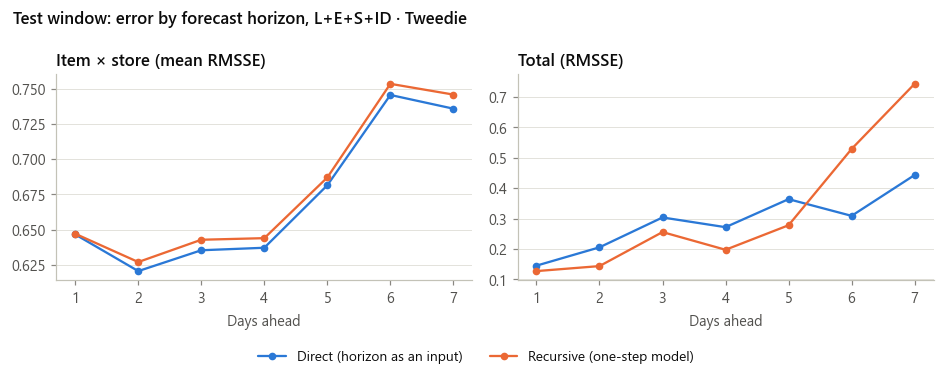

In [8]:
def by_horizon(f, ev):
    a = ev.actual[12]
    err = ((f - a) ** 2).reshape(len(a), m5.EVAL_WEEKS, m5.HORIZON).mean(axis=1)  # mean over the 4 origins
    item = np.sqrt(err / ev.scale[12][:, None]).mean(axis=0)
    tot = (f.sum(axis=0) - a.sum(axis=0)) ** 2
    total = np.sqrt(tot.reshape(m5.EVAL_WEEKS, m5.HORIZON).mean(axis=0) / ev.scale[1][0])
    return pd.DataFrame({"Item × store (mean RMSSE)": item, "Total (RMSSE)": total}, index=range(1, m5.HORIZON + 1))


strategy = pd.DataFrame([{"inputs": b.split(" · ")[0], "strategy": "recursive" if rec else "direct",
                          "WRMSSE valid": summary.loc[m, "WRMSSE valid"], "WRMSSE test": summary.loc[m, "WRMSSE test"],
                          **{k: levels.loc[m, k] for k in KEEP}, "RMSSE mean test": summary.loc[m, "RMSSE mean test"]}
                         for b in ["L+E+S · Tweedie", "L+E+S+ID · Tweedie"] for rec, m in [(False, b), (True, f"{b} · recursive")]]
                        ).set_index(["inputs", "strategy"])
strategy.to_csv(RESULTS / "strategy_test.csv")
direct, recursive = by_horizon(test[BEST], ev_test), by_horizon(test[f"{BEST} · recursive"], ev_test)
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.1))
for ax, col in zip(axes, direct.columns):
    ax.plot(direct.index, direct[col], color=SERIES[0], marker="o", ms=4, label="Direct (horizon as an input)")
    ax.plot(recursive.index, recursive[col], color=SERIES[1], marker="o", ms=4, label="Recursive (one-step model)")
    ax.set_title(col)
    ax.set_xlabel("Days ahead")
fig.suptitle(f"Test window: error by forecast horizon, {BEST}", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.02), ncols=2)
savefig(fig, "strategy_by_horizon_test", subdir="evaluation")
plt.show()
strategy.style.format("{:.3f}")

## 6. Significance and stability (Section 7.9)

**Planned comparisons.** Two-sided Wilcoxon signed-rank tests on the RMSSE of the 30,490 series, with the Holm
correction over the family below. With this many series almost any difference is statistically significant,
so the size of the difference and the share of series on which the second model is better are given next
to the p-values.

In [9]:
T = "Tweedie"
PLANNED = {
    "7.1 best global vs seasonal naive": ("Seasonal naive", BEST),
    "7.1 best global vs ADIDA": ("ADIDA", BEST),
    "7.1 best global vs TSB": ("TSB", BEST),
    "7.1 lags only (L) vs ADIDA": ("ADIDA", f"L · {T}"),
    "7.3 Tweedie vs MSE (L+E+S)": ("L+E+S · MSE", f"L+E+S · {T}"),
    "7.3 Tweedie vs Poisson (L+E+S)": ("L+E+S · Poisson", f"L+E+S · {T}"),
    "7.4 L+E vs L": (f"L · {T}", f"L+E · {T}"),
    "7.4 L+E+S vs L+E": (f"L+E · {T}", f"L+E+S · {T}"),
    "7.4 L+E+S+ID vs L+E+S": (f"L+E+S · {T}", f"L+E+S+ID · {T}"),
    "7.2 all series vs per store": (f"{BEST} · per store", BEST),
    "7.2 all series vs per demand class": (f"{BEST} · per demand class", BEST),
    "7.7 recursive vs direct": (BEST, f"{BEST} · recursive"),
}
tests = S.wilcoxon_holm(rmsse, PLANNED).loc[list(PLANNED)]
tests["mean first"] = [rmsse[a].mean() for a in tests["A"]]
tests["mean second"] = [rmsse[b].mean() for b in tests["B"]]
tests["mean difference (second − first)"] = -tests["mean_diff"]
tests["second better (share of series)"] = [(rmsse[b] < rmsse[a]).mean() for a, b in zip(tests["A"], tests["B"])]
tests["WRMSSE first"] = [summary.loc[a, "WRMSSE test"] for a in tests["A"]]
tests["WRMSSE second"] = [summary.loc[b, "WRMSSE test"] for b in tests["B"]]
tests = tests.rename(columns={"A": "first", "B": "second"}).drop(columns=["mean_diff", "p_raw"])
tests = tests[["first", "second", "mean first", "mean second", "mean difference (second − first)",
               "second better (share of series)", "p_holm", "WRMSSE first", "WRMSSE second"]]
tests.to_csv(RESULTS / "planned_tests.csv")
tests.style.format("{:.3f}", subset=["mean first", "mean second", "WRMSSE first", "WRMSSE second"]).format(
    "{:+.4f}", subset=["mean difference (second − first)"]).format("{:.1%}", subset=["second better (share of series)"]).format(
    "{:.2g}", subset=["p_holm"])

,first,second,mean first,mean second,mean difference (second − first),second better (share of series),p_holm,WRMSSE first,WRMSSE second
contrast,,,,,,,,,
7.1 best global vs seasonal naive,Seasonal naive,L+E+S+ID · Tweedie,1.033,0.750,-0.2830,97.7%,0,0.901,0.572
7.1 best global vs ADIDA,ADIDA,L+E+S+ID · Tweedie,0.762,0.750,-0.0118,57.3%,1.2e-304,0.945,0.572
7.1 best global vs TSB,TSB,L+E+S+ID · Tweedie,0.766,0.750,-0.0158,67.4%,0,0.956,0.572
7.1 lags only (L) vs ADIDA,ADIDA,L · Tweedie,0.762,0.759,-0.0028,46.5%,4.7e-11,0.945,0.697
7.3 Tweedie vs MSE (L+E+S),L+E+S · MSE,L+E+S · Tweedie,0.753,0.752,-0.0010,52.7%,6.1e-28,0.618,0.602
7.3 Tweedie vs Poisson (L+E+S),L+E+S · Poisson,L+E+S · Tweedie,0.752,0.752,-0.0001,50.6%,0.028,0.625,0.602
7.4 L+E vs L,L · Tweedie,L+E · Tweedie,0.759,0.759,-0.0002,51.4%,0.00011,0.697,0.621
7.4 L+E+S vs L+E,L+E · Tweedie,L+E+S · Tweedie,0.759,0.752,-0.0065,61.9%,0,0.621,0.602
7.4 L+E+S+ID vs L+E+S,L+E+S · Tweedie,L+E+S+ID · Tweedie,0.752,0.750,-0.0022,54.4%,1.1e-79,0.602,0.572


**All models together.** Friedman test on the ranks of the models within each series (1 = lowest RMSSE), and
the Nemenyi critical difference: two models whose mean ranks differ by less than CD are not distinguishable.

Friedman chi2 = 83,676, p = 0; Nemenyi CD = 0.114 (14 models, 30,490 series)


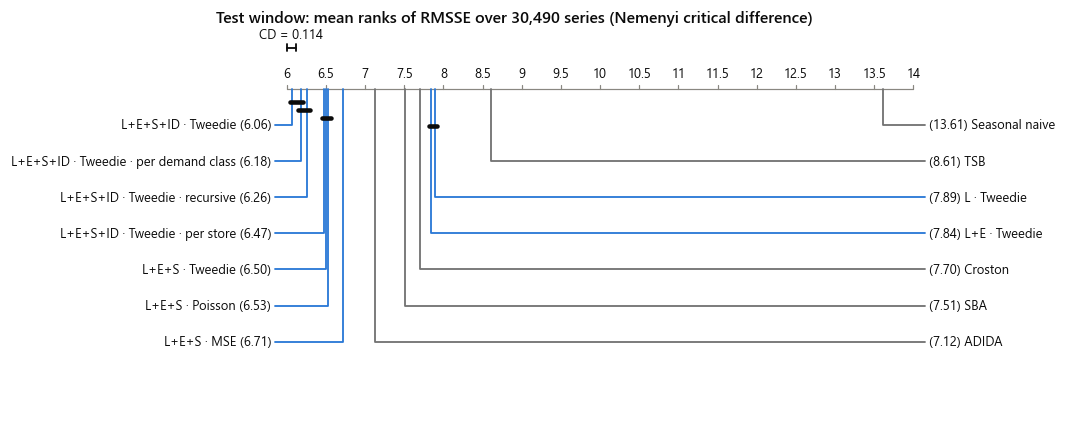

,mean rank,RMSSE mean test,WRMSSE test
L+E+S+ID · Tweedie,6.065,0.750,0.572
L+E+S+ID · Tweedie · per demand class,6.177,0.751,0.577
L+E+S+ID · Tweedie · recursive,6.261,0.753,0.613
L+E+S+ID · Tweedie · per store,6.473,0.752,0.565
L+E+S · Tweedie,6.503,0.752,0.602
L+E+S · Poisson,6.528,0.752,0.625
L+E+S · MSE,6.713,0.753,0.618
ADIDA,7.121,0.762,0.945
SBA,7.505,0.771,0.961
Croston,7.695,0.773,0.972


In [10]:
CD_MODELS = ["Seasonal naive", "Croston", "SBA", "TSB", "ADIDA"] + [m for m in GLOBAL if m.endswith(T)] + [
    "L+E+S · MSE", "L+E+S · Poisson", f"{BEST} · per store", f"{BEST} · per demand class", f"{BEST} · recursive"]
fn = S.friedman_nemenyi(rmsse[CD_MODELS])
ranks = fn["mean_ranks"].to_frame("mean rank")
ranks["RMSSE mean test"] = summary.loc[ranks.index, "RMSSE mean test"]
ranks["WRMSSE test"] = summary.loc[ranks.index, "WRMSSE test"]
ranks.to_csv(RESULTS / "friedman_ranks.csv")
print(f"Friedman chi2 = {fn['chi2']:,.0f}, p = {fn['p']:.3g}; Nemenyi CD = {fn['cd']:.3f} ({len(CD_MODELS)} models, {len(rmsse):,} series)")
fig, ax = plt.subplots(figsize=(9, 4.6))
S.plot_cd_diagram(ax, fn["mean_ranks"], fn["cd"], {m: (SERIES[0] if m in XGB else "0.45") for m in CD_MODELS})
ax.set_title("Test window: mean ranks of RMSSE over 30,490 series (Nemenyi critical difference)", loc="left", fontsize=10.5)
savefig(fig, "cd_diagram_test", subdir="evaluation")
plt.show()
ranks

**Seeds.** The best variant was trained with five seeds (the seed changes the row and column subsampling and
the horizons drawn per origin). Differences between models that are smaller than the spread below cannot
be told apart from the effect of the seed.

In [11]:
key = [k for k in raw.files if "_seed" not in k and not k.startswith(("benchmark_", "sample100_")) and label(k) == BEST][0]
runs = {0: raw[key], **{int(k.rsplit("seed", 1)[1]): f for k, f in seeds_fc.items() if k.startswith(key + "_seed")}}
vseeds = pd.read_csv(ROOT / "results" / "global_xgb" / "seeds_valid.csv", index_col=0)
seeds = pd.DataFrame({s: {"WRMSSE valid": vseeds.loc[s, "WRMSSE"], "WRMSSE test": ev_test.wrmsse(f)["all"],
                          **{f"{LEVEL_NAMES[k]} test": ev_test.wrmsse(f)[k] for k in (1, 3, 8, 12)},
                          "RMSSE mean test": ev_test.bottom(f)["rmsse"].mean()} for s, f in sorted(runs.items())}).T
seeds.index.name = "seed"
seeds.to_csv(RESULTS / "seeds_test.csv")
print(BEST)
pd.concat([seeds, seeds.agg(["mean", "std", "min", "max"])]).style.format("{:.4f}")

L+E+S+ID · Tweedie


,WRMSSE valid,WRMSSE test,Total test,Store test,Store × category test,Item × store test,RMSSE mean test
0,0.5708,0.5720,0.3055,0.4764,0.5557,0.8337,0.7499
1,0.5726,0.5703,0.3080,0.4769,0.5555,0.8347,0.7501
2,0.5753,0.5682,0.3030,0.4734,0.5507,0.8340,0.7501
3,0.5694,0.5687,0.3035,0.4708,0.5513,0.8337,0.7501
4,0.5682,0.5732,0.3068,0.4813,0.5592,0.8346,0.7501
mean,0.5713,0.5705,0.3054,0.4757,0.5545,0.8341,0.7500
std,0.0028,0.0021,0.0021,0.0040,0.0035,0.0005,0.0001
min,0.5682,0.5682,0.3030,0.4708,0.5507,0.8337,0.7499
max,0.5753,0.5732,0.3080,0.4813,0.5592,0.8347,0.7501


## 7. Where the classical methods still win (Section 7.10)

Series on which a classical method has a lower RMSSE than the best global variant, by demand class and by
how much of the history is zero. The level table of Section 2 gives the other side: the levels on which the
classical methods are closest.

In [12]:
classical = rmsse[["Croston", "SBA", "TSB", "ADIDA"]].min(axis=1)  # best of the four on each series, an upper bound for them
zero_bin = pd.cut(stats["zero_share"], [0, 0.5, 0.7, 0.8, 0.9, 0.95, 1.0], include_lowest=True)
tbl = {}
for name, key in [("demand class", pd.Series(cls)), ("share of zero days in the history", zero_bin)]:
    g = pd.DataFrame({"series": 1, "ADIDA better": rmsse["ADIDA"] < rmsse[BEST], "TSB better": rmsse["TSB"] < rmsse[BEST],
                      "best of four intermittent methods better": classical < rmsse[BEST],
                      f"RMSSE {BEST}": rmsse[BEST], "RMSSE ADIDA": rmsse["ADIDA"]}).groupby(key.to_numpy(), observed=True)
    t = g.mean()
    t["series"] = g["series"].sum()
    tbl[name] = t
where = pd.concat(tbl)
where.to_csv(RESULTS / "where_classical_wins_test.csv")
flat = (test[BEST].std(axis=1) < 1e-6).mean()
print(f"ADIDA has a lower RMSSE than {BEST} on {(rmsse['ADIDA'] < rmsse[BEST]).mean():.1%} of all series")
where.style.format("{:.3f}").format("{:,.0f}", subset=["series"]).format(
    "{:.1%}", subset=["ADIDA better", "TSB better", "best of four intermittent methods better"])

ADIDA has a lower RMSSE than L+E+S+ID · Tweedie on 42.7% of all series


## Key findings

All numbers are from the test window, which no model has seen.

1. **Global XGBoost against the classical methods (7.1).** The variant chosen on the validation window
   (L+E+S+ID, Tweedie) has WRMSSE 0.572 on the test window, against 0.901 for the seasonal naive method and
   0.945 for ADIDA. Its validation score was 0.571, so the tuning did not overfit the validation window. On
   single series the gain is small: mean RMSSE 0.750 against 0.762 for ADIDA, and a lower RMSSE on 57% of the
   series.
2. **Inputs (7.4).** WRMSSE falls with every group: 0.70 (L), 0.62 (L+E), 0.60 (L+E+S), 0.57 (L+E+S+ID). The
   inputs known in advance bring the largest gain, and almost all of it on the aggregated levels: the mean
   RMSSE of single series does not change from L to L+E (0.759) and falls to 0.752 and 0.750 with the
   statistics and the identifiers. A model with lags only is no better than ADIDA on single series (lower
   RMSSE on 47% of them).
3. **Loss (7.3).** No loss wins consistently: Tweedie is best with L+E+S (0.602 against 0.618 and 0.625), MSE
   with L, Poisson with L+E, and the differences in mean RMSSE are 0.001 or less. The loss matters far less
   than the inputs.
4. **Pooling (7.2).** On all series, one model, one model per store and one per demand class are within 0.01
   of each other in WRMSSE (0.565–0.577 with L+E+S+ID) and within 0.002 in mean RMSSE; the model on all series
   has the best mean rank. Without the identifiers, models per store are better than one model (0.584 against
   0.602). On the sample of 100 series the models per series are the worst: mean RMSSE 0.77 against 0.71–0.72
   for the model on all series (significant only with L+E+S), and no better than ADIDA (0.74). Their
   validation score of 0.67 was selection bias. A model trained on the 100 series alone matches the model on
   all series.
5. **By level and by class (7.5, 7.6).** The advantage over the classical methods is largest at the top of
   the hierarchy (total: 0.31 against 0.64 for the seasonal naive method) and smallest at the bottom
   (item × store: 0.834 against 0.874 for ADIDA). By demand class the gain in mean RMSSE over ADIDA is 0.03
   for smooth and erratic series, 0.017 for lumpy and 0.008 for intermittent series.
6. **Strategy (7.7).** The recursive model is worse than the direct one on the test window (WRMSSE 0.613
   against 0.572; 0.666 against 0.602 with L+E+S), although it was better on the validation window (0.534
   against 0.571). Its validation advantage did not carry over.
7. **Significance and stability (7.9).** All planned comparisons are significant after the Holm correction,
   which with 30,490 series says little; the sizes of the differences are in the table. In the Friedman–Nemenyi
   ranking the six XGBoost models with L+E+S or L+E+S+ID are ahead of every classical method, but ADIDA, SBA
   and Croston rank ahead of the XGBoost models with L and L+E. Five seeds of the best variant give WRMSSE
   0.568–0.573 and the same mean RMSSE to three decimals.
8. **Where the classical methods still win (7.10).** ADIDA has a lower RMSSE than the best global model on 43%
   of all series and on 45% of the intermittent ones; the share grows with the share of zero days, from 35%
   (under half of the days zero) to 54% (90–95% zero). On very sparse series the two are practically tied.
9. **Limits.** One test window of 28 days; 30 tuning trials per variant; the partially global and recursive
   models were not tuned; the models per series exist for 100 series only.